# 1. Encoding Numerical Features

In [13]:
import pandas as pd
import numpy as np 

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.preprocessing import KBinsDiscretizer
from sklearn.compose import ColumnTransformer

In [14]:
df = pd.read_csv('E:/BRAINWORk/Machine Learning/placement-project/DataSets/train.csv', usecols=['Age','Fare','Survived'])

In [15]:
df.dropna(inplace=True)

In [16]:
df.shape

(714, 3)

In [17]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [21]:
X = df.iloc[:,1:]
y = df.iloc[:,0]

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [23]:
X_train.head(2)

,Age,Fare
328,31.0,20.5250
73,26.0,14.4542


In [24]:
clf = DecisionTreeClassifier()

In [25]:
clf.fit(X_train,y_train)
y_pred = clf.predict(X_test)

In [26]:
accuracy_score(y_test,y_pred)

0.6153846153846154

In [27]:
np.mean(cross_val_score(DecisionTreeClassifier(),X,y,cv=10,scoring='accuracy'))

np.float64(0.6345070422535211)

In [33]:
kbin_age = KBinsDiscretizer(n_bins=5, encode='ordinal',strategy='quantile')
kbin_fare = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='quantile')

In [34]:
trf = ColumnTransformer([
    ('first', kbin_age,[0]),
    ('second',kbin_fare,[1])
])

In [35]:
X_train_trf = trf.fit_transform(X_train)
X_test_trf = trf.transform(X_test)

In [36]:
trf.named_transformers_['first'].n_bins_

array([5])

In [38]:
trf.named_transformers_['first'].bin_edges_

array([array([ 0.42, 19.  , 25.  , 32.  , 42.  , 80.  ])], dtype=object)

In [40]:
output = pd.DataFrame({
    'age':X_train['Age'],
    'age_trf':X_train_trf[:,0],
    'fare':X_train['Fare'],
    'fare_trf':X_train_trf[:,1]
})

In [42]:
output['age_labels'] = pd.cut(x=X_train['Age'],
                              bins = trf.named_transformers_['first'].bin_edges_[0].tolist())
output['fare_labels'] = pd.cut(x=X_train['Fare'],
                              bins= trf.named_transformers_['second'].bin_edges_[0].tolist())

In [43]:
output.sample(5)

,age,age_trf,fare,fare_trf,age_labels,fare_labels
644,0.75,0.0,19.2583,2.0,"(0.42, 19.0]","(13.0, 26.0]"
16,2.00,0.0,29.1250,3.0,"(0.42, 19.0]","(26.0, 51.479]"
92,46.00,4.0,61.1750,4.0,"(42.0, 80.0]","(51.479, 512.329]"
239,33.00,3.0,12.2750,1.0,"(32.0, 42.0]","(7.896, 13.0]"
22,15.00,0.0,8.0292,1.0,"(0.42, 19.0]","(7.896, 13.0]"


In [44]:
clf = DecisionTreeClassifier()
clf.fit(X_train_trf,y_train)
y_pred2 = clf.predict(X_test_trf)

In [45]:
accuracy_score(y_test, y_pred2)

0.6433566433566433

In [46]:
X_trf = trf.fit_transform(X)
np.mean(cross_val_score(DecisionTreeClassifier(),X,y,cv=10,scoring='accuracy'))

np.float64(0.6330985915492958)

In [48]:

def discretize(bins, strategy):
    # 1. Initialize discretizers for Age and Fare
    kbin_age = KBinsDiscretizer(n_bins=bins, encode='ordinal', strategy=strategy)
    kbin_fare = KBinsDiscretizer(n_bins=bins, encode='ordinal', strategy=strategy)
    
    # 2. Bundle them together using ColumnTransformer applied to column indexes 0 and 1
    trf = ColumnTransformer([
        ('first', kbin_age, [0]),
        ('second', kbin_fare, [1])
    ])
    
    # 3. Fit and transform the feature matrix X
    X_trf = trf.fit_transform(X)
    
    # 4. Evaluate using cross-validation (Note: evaluate on the transformed data 'X_trf' instead of raw 'X')
    # FIX: The original image prints cross_val_score on 'X' instead of 'X_trf'
    print(np.mean(cross_val_score(DecisionTreeClassifier(), X_trf, y, cv=10, scoring='accuracy')))
    
    # 5. Plotting distributions before and after discretization
    plt.figure(figsize=(14, 4))
    
    # Left Plot: Original Age distribution
    plt.subplot(121)
    plt.hist(X['Age'])
    plt.title("Before")
    
    # Right Plot: Binned/Discretized Age distribution
    plt.subplot(122)
    plt.hist(X_trf[:, 0], color='red')
    plt.title("After")
    
    plt.show()

0.6807316118935838


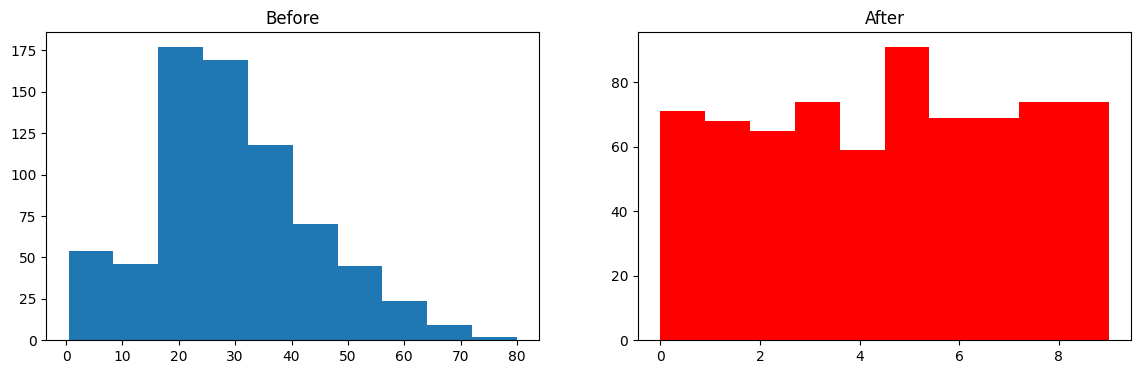

In [49]:
discretize(10,'quantile')

0.6864632237871675


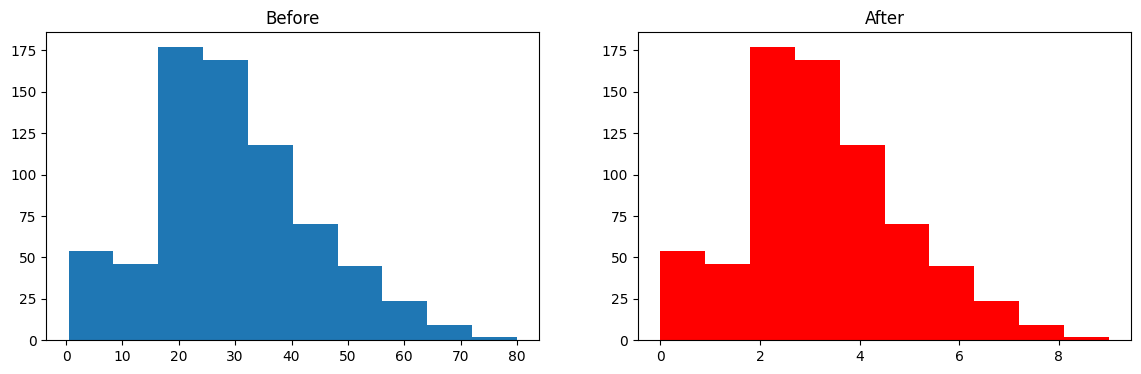

In [50]:
discretize(10,'uniform')

0.6723982785602504


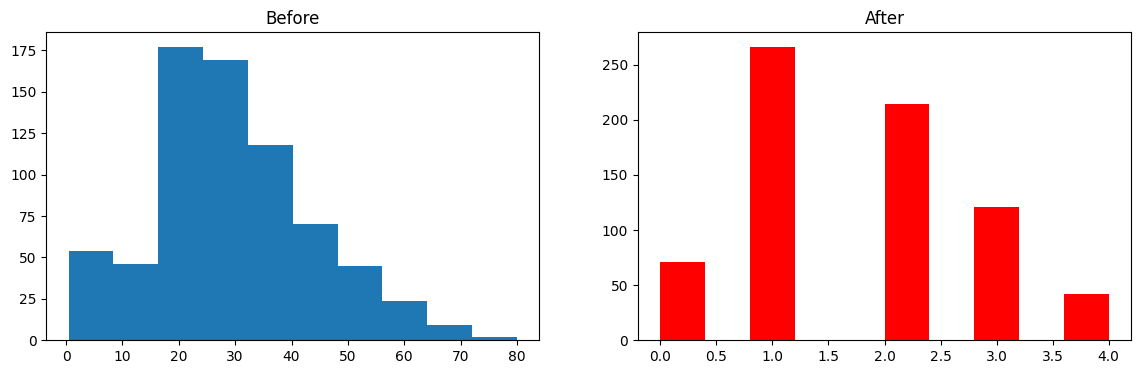

In [51]:
discretize(5,'kmeans')

# Binarization


In [74]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.compose import ColumnTransformer

In [75]:
df = pd.read_csv('E:/BRAINWORk/Machine Learning/placement-project/DataSets/train.csv')[['Age', 'Fare', 'SibSp', 'Parch', 'Survived']]

In [76]:
df.dropna(inplace=True)

In [77]:
df.head()

,Age,Fare,SibSp,Parch,Survived
0,22.0,7.2500,1,0,0
1,38.0,71.2833,1,0,1
2,26.0,7.9250,0,0,1
3,35.0,53.1000,1,0,1
4,35.0,8.0500,0,0,0


In [78]:
df['family'] = df['SibSp'] + df['Parch']

In [79]:
df.drop(columns=['SibSp','Parch'], inplace=True)

In [80]:
df.head()

,Age,Fare,Survived,family
0,22.0,7.2500,0,1
1,38.0,71.2833,1,1
2,26.0,7.9250,1,0
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [81]:
X = df.drop(columns=['Survived'])
y = df['Survived']

In [82]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [83]:
X_train.head()

,Age,Fare,family
328,31.0,20.5250,2
73,26.0,14.4542,1
253,30.0,16.1000,1
719,33.0,7.7750,0
666,25.0,13.0000,0


In [84]:
# Without Binarization

clf = DecisionTreeClassifier()
clf.fit(X_train,y_train)
y_pred = clf.predict(X_test)
accuracy_score(y_test,y_pred)

0.6153846153846154

In [85]:
np.mean(cross_val_score(DecisionTreeClassifier(), X,y,cv=10,scoring='accuracy'))


np.float64(0.6429381846635367)

In [86]:
# Applying Binarization

from sklearn.preprocessing import Binarizer

In [87]:
trf = ColumnTransformer([
    ('bin',Binarizer(copy=False), ['family'])
],remainder='passthrough')

In [88]:
X_train_trf = trf.fit_transform(X_train)
X_test_trf = trf.transform(X_test)

In [89]:
pd.DataFrame(X_train_trf,columns=['family', 'Age','Fare'])

,family,Age,Fare
0,1.0,31.0,20.5250
1,1.0,26.0,14.4542
2,1.0,30.0,16.1000
3,0.0,33.0,7.7750
4,0.0,25.0,13.0000
...,...,...,...
566,1.0,46.0,61.1750
567,0.0,25.0,13.0000
568,0.0,41.0,134.5000
569,1.0,33.0,20.5250


In [91]:
clf = DecisionTreeClassifier()
clf.fit(X_train_trf,y_train)
y_pred2 = clf.predict(X_test_trf)

accuracy_score(y_test,y_pred2)

0.6013986013986014

In [ ]:
X_trf = trf.fit_transform(X)
# Now cross_val_score will receive the array-like data it expects
mean_accuracy = np.mean(cross_val_score(DecisionTreeClassifier(), X_trf, y, cv=10, scoring='accuracy'))
print(mean_accuracy)

0.6276017214397495
